In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Base de Dados Integrada - Linha de Usinagem & Montagem
dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex']
oee_diario = [82, 85, 79, 88, 91]  # Eficiência Global (%)

turnos = ['Turno A', 'Turno B', 'Turno C']
pecas_produzidas = [460, 425, 490]

np.random.seed(42)
tempos_ciclo = np.random.normal(loc=32.0, scale=0.9, size=200)  # 200 ciclos (Alvo = 32.0s)

temperatura_maquina = [45, 48, 52, 55, 58, 61, 64, 67, 70, 73]
taxa_refugo = [0.8, 0.9, 1.1, 1.3, 1.6, 2.0, 2.5, 3.1, 3.8, 4.4]


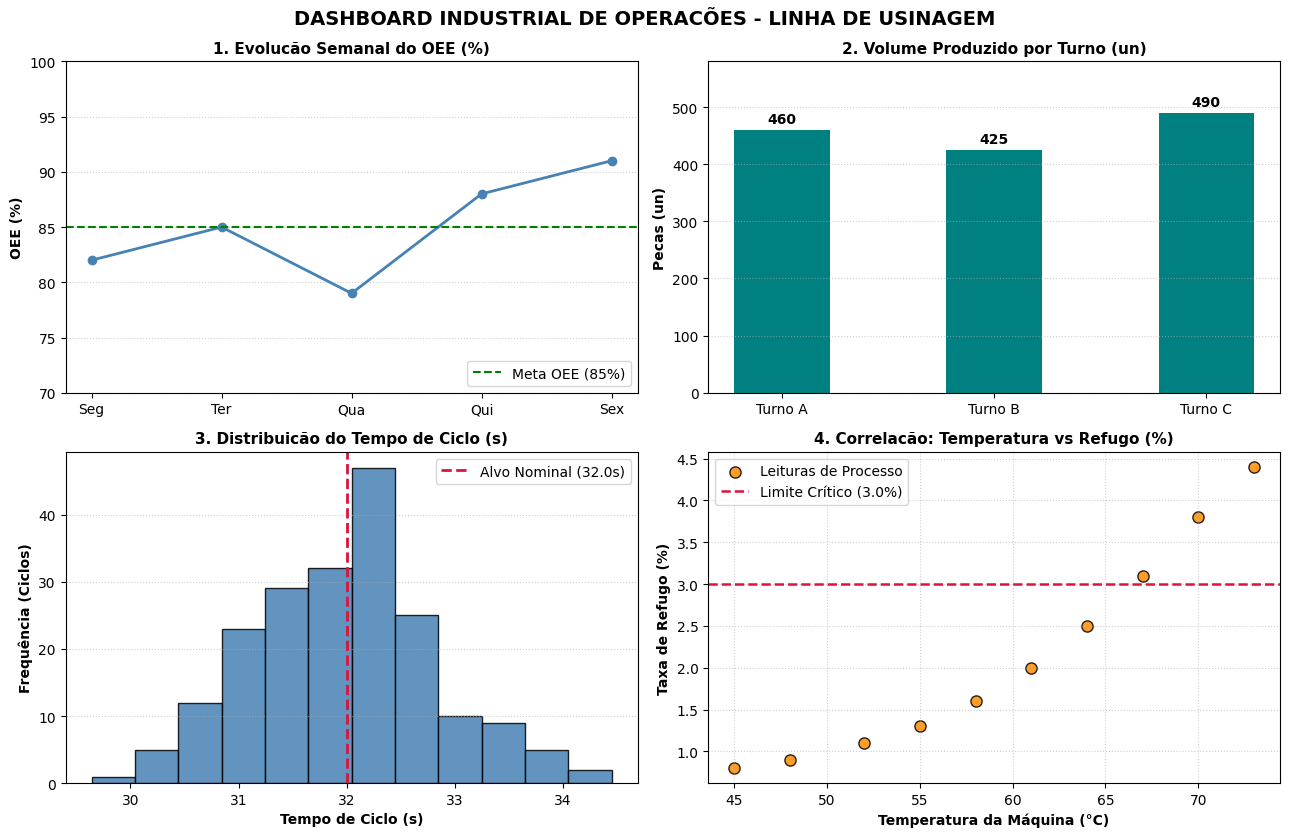

In [8]:
# Criando a grade de 2 linhas e 2 colunas
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))


# --- GRÁFICO 1 (ESQUERDA -> ax[0, 0]) --- linhas
ax[0, 0].plot(
    dias,
    oee_diario,
    marker='o',
    color='steelblue',
    linewidth=2,
)
ax[0, 0].set_ylim( 70, 100)
ax[0, 0].set_title('1. Evolucão Semanal do OEE (%)', fontsize=11, fontweight='bold')
ax[0, 0].set_ylabel('OEE (%)', fontweight='bold')
ax[0, 0].grid(axis='y', linestyle=':', alpha=0.6)

# Linha de limite critico
ax[0, 0].axhline(
     y=85,
    color='green',
    linestyle='--',
    linewidth=1.5,
    label='Meta OEE (85%)',
)
ax[0, 0].legend(loc='lower right')

# --- GRÁFICO 2 (DIREITA -> ax[0, 1]) --- barras
barras_1 = ax[0, 1].bar(
    turnos,
    pecas_produzidas,
    color='teal',
    width=0.45
)
ax[0, 1].bar_label(barras_1, padding=3, fontweight='bold')
ax[0, 1].set_ylim(0, 580)
ax[0, 1].set_title('2. Volume Produzido por Turno (un)', fontsize=11, fontweight='bold')
ax[0, 1].set_ylabel('Pecas (un)', fontweight='bold')
ax[0, 1].grid(axis='y', linestyle=':', alpha=0.6)

# --- GRÁFICO 3 (Canto Inferior Esquerdo -> ax[1, 0]) --- Histograma
ax[1, 0].hist(
    tempos_ciclo,
    bins=12,
    color='steelblue',
    edgecolor='black',
    alpha=0.85,
)
# Linhas verticais de referencia técnica (Nominal)
ax[1, 0].axvline(32.0, color='crimson', linestyle='--', linewidth=2, label='Alvo Nominal (32.0s)')
# Formatacão Técnica
ax[1, 0].set_title(
    '3. Distribuicão do Tempo de Ciclo (s)',
    fontsize=11,
    fontweight='bold',
)
ax[1, 0].set_xlabel('Tempo de Ciclo (s)', fontweight='bold')
ax[1, 0].set_ylabel('Frequência (Ciclos)', fontweight='bold')
ax[1, 0].legend(loc='upper right')
ax[1, 0].grid(axis='y', linestyle=':', alpha=0.6)

# --- GRÁFICO 4 (Canto Inferior Direito -> ax[1, 1])--- scater
ax[1, 1].scatter(
    temperatura_maquina,
    taxa_refugo,
    color='darkorange',
    s=65,
    edgecolor='black',
    alpha=0.85,
    label='Leituras de Processo',
)

#  Linha horizontal de alerta máximo (3.0%)
ax[1, 1].axhline(3.0, color='crimson', linestyle='--', linewidth=1.8, label='Limite Crítico (3.0%)')

#  Formatacão Técnica
ax[1, 1].set_title(
    '4. Correlacão: Temperatura vs Refugo (%)',
    fontsize=11,
    fontweight='bold',
)
ax[1, 1].set_xlabel('Temperatura da Máquina (°C)',fontweight='bold')
ax[1, 1].set_ylabel('Taxa de Refugo (%)', fontweight='bold')
ax[1, 1].legend(loc='upper left')
ax[1, 1].grid(True, linestyle=':', alpha=0.6)

fig.suptitle(
    'DASHBOARD INDUSTRIAL DE OPERACÕES - LINHA DE USINAGEM',
    fontsize=14,
    fontweight='bold',
)


# 3. Ajuste automático de espacamento para os textos não encostarem
plt.tight_layout()

fig.savefig('dashboard_industrial.png', dpi=300, bbox_inches='tight')

# Exibindo o resultado
plt.show()